<a href="https://colab.research.google.com/github/LayamAlamri0/international-airpassengers-project/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone project - Air passengers, start to finish

The course pipeline, on this series: explore it, decompose it, set the
benchmark floor, check what the floor leaves on the table, fit a model
through the framework, cross-validate, and read the result against the
floor.

**What is graded is the process, not the number.** A low MASE from one
holdout with no intervals scores worse than an honest analysis that
concludes the benchmark wins.

Full rules and report requirements: `brief.md`. Grading: `rubric.md`. This
notebook is the first deliverable; it should run top to bottom in under ten
minutes on Colab.

This notebook is a starter. You may swap in your own series or your own
framework - see "Your own data or method" in `brief.md`.

In [1]:
import sys

if "google.colab" in sys.modules:
    !git clone -q https://github.com/SDAIAAcademy/international-airpassengers-project.git /content/proj
    %cd /content/proj
    !pip install -q -e .

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coursekit import plotting as P
from coursekit import scoring

P.use_course_style()

SEASON_LENGTH = 12
H = 12            # forecast horizon for cross-validation
H_REPORT = 24     # forecast horizon for the report

/content/proj
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 501.8/501.8 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.7/348.7 kB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.4/50.4 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 kB 5.2 MB/s eta 0:00:00
  Building editable for international-airpassengers-project (pyproject.toml) ... done


/content/proj/coursekit/plotting.py:599: SyntaxWarning: invalid escape sequence '\h'
  :math:`\hat{F}` whose characteristics do not change over time -- so that a
/content/proj/coursekit/plotting.py:676: SyntaxWarning: invalid escape sequence '\h'
  """Draw the h-step errors :math:`e_{t+h|t} = y_{t+h} - \hat{y}_{t+h|t}`.


---
# 0. The data

Monthly international air passenger numbers, 1949-01 to 1960-12: 144
observations, no gaps. The Box & Jenkins classic (1970) — twelve years of
growth, and a year that does not repeat the same way twice.

Fetched from statsmodels' R-datasets on first run; no download step.

In [2]:
from statsmodels.datasets import get_rdataset

raw = get_rdataset("AirPassengers").data
t = raw["time"].astype(float).to_numpy()
years = np.floor(t).astype(int)
months = np.clip(np.round((t - years) * 12).astype(int) + 1, 1, 12)
df = pd.DataFrame({
    "unique_id": "Air passengers (Box & Jenkins)",
    "ds": pd.to_datetime(pd.Series(years).astype(str) + "-" +
                         pd.Series(months).astype(str).str.zfill(2) + "-01"),
    "y": raw["value"].astype(float),
}).sort_values("ds").reset_index(drop=True)
df.head()

,unique_id,ds,y
0,Air passengers (Box & Jenkins),1949-01-01,112.0
1,Air passengers (Box & Jenkins),1949-02-01,118.0
2,Air passengers (Box & Jenkins),1949-03-01,132.0
3,Air passengers (Box & Jenkins),1949-04-01,129.0
4,Air passengers (Box & Jenkins),1949-05-01,121.0


In [3]:
n_obs = len(df)
range_ = (df["ds"].min(), df["ds"].max())

expected_months = pd.date_range(
    start=range_[0], end=range_[1], freq="MS"
)
n_gaps = len(expected_months.difference(df["ds"]))

print(
    f"{n_obs} months, {range_[0].date()} "
    f"to {range_[1].date()}, {n_gaps} gaps"
)

144 months, 1949-01-01 to 1960-12-01, 0 gaps


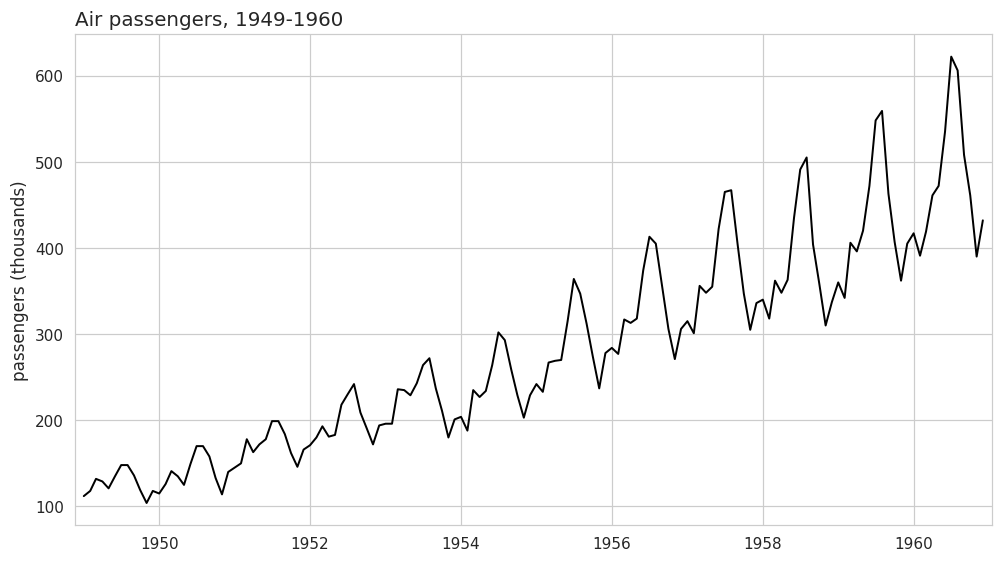

In [4]:
P.plot_series(df, title="Air passengers, 1949-1960",
              ylabel="passengers (thousands)", xlabel="")
plt.show()

Passenger numbers rise over the twelve years, with peaks around the middle of each year and lower numbers near the beginning and end. The gap between the yearly highs and lows grows as passenger numbers increase.

**First read.** Before any model, write two sentences that describe this
series in plain language - the kind a non-forecaster could repeat. (Trend?
Seasonality? What happens to the swings as the level grows? Cycle?) These two
sentences belong at the top of your report.

---
# 1. Exploration and shape

The Day 1 toolkit, in order. Every chart should carry its claim: a title that
says what it shows, not just "series".

**1.1 Decompose.** STL, additive, period 12. Read all three panels: which
component does the work, and what does the remainder look like?

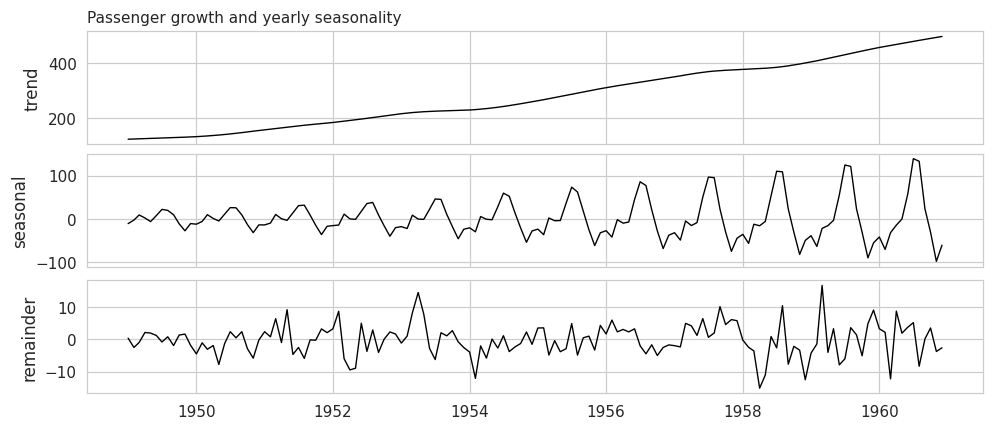

In [5]:
from statsmodels.tsa.seasonal import STL

stl = STL(df["y"], period=12).fit()

dcmp = pd.DataFrame({
    "ds": df["ds"],
    "trend": stl.trend,
    "seasonal": stl.seasonal,
    "remainder": stl.resid
})

P.decomposition_plot(
    dcmp,
    cols=["trend", "seasonal", "remainder"],
    title="Passenger growth and yearly seasonality",
    x="ds"
)
plt.show()

The trend explains most of the long-term increase in passenger numbers. The seasonal component shows a repeating yearly pattern, with larger swings in later years. The remainder is much smaller and fluctuates around zero, although some spikes remain.

**1.2 Trend and seasonal strength.** The two numbers from Day 1, computed
the same way (textbook formulas on the STL components). State what they
imply for model choice.

In [6]:
remainder = dcmp["remainder"]

trend_strength = max(
    0,
    1 - remainder.var()
    / (dcmp["trend"] + remainder).var()
)

seasonal_strength = max(
    0,
    1 - remainder.var()
    / (dcmp["seasonal"] + remainder).var()
)

print(f"trend strength: {trend_strength:.2f}")
print(f"seasonal strength: {seasonal_strength:.2f}")

trend strength: 1.00
seasonal strength: 0.99


Trend strength rounds to 1.00 and seasonal strength to 0.99, so both patterns are very strong. This supports testing models that capture growth and yearly seasonality, such as seasonal ETS or seasonal ARIMA, against the seasonal naive benchmark.

**1.3 Autocorrelation.** The ACF of the raw series. What is at lag 12?
At 24? What does that tell you before you fit anything?

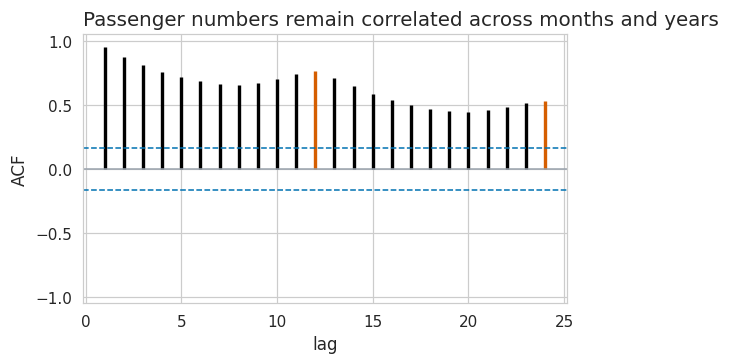

In [7]:
P.acf_plot(
    df["y"],
    nlags=24,
    highlight_every=12,
    title="Passenger numbers remain correlated across months and years"
)
plt.show()

The correlations stay positive and decline slowly, reflecting the strong upward trend. Local peaks at 12 and 24 months also support a yearly seasonal pattern: passenger numbers are related to those in the same month one and two years earlier.

---
# 2. The floor

The seasonal naive is the first model you fit on any series - not as a
formality, as the thing everything else has to beat. Fit it, check what it
leaves on the table, and give it an honest interval.

In [8]:
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive, Naive

floor_sf = StatsForecast(
    models=[
        SeasonalNaive(season_length=SEASON_LENGTH),
        Naive()
    ],
    freq="MS",
    n_jobs=1
)

floor_fc = floor_sf.forecast(
    df=df,
    h=H_REPORT,
    level=scoring.LEVELS
)

floor_fc.head()

,unique_id,ds,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,...,Naive-lo-20,Naive-lo-40,Naive-lo-60,Naive-lo-80,Naive-lo-95,Naive-hi-20,Naive-hi-40,Naive-hi-60,Naive-hi-80,Naive-hi-95
0,Air passengers (Box & Jenkins),1961-01-01,417.0,407.799511,397.956005,386.435898,370.4595,345.822448,426.200489,436.043995,...,423.459566,414.322245,403.628605,388.798374,365.928814,440.540434,449.677755,460.371395,475.201626,498.071186
1,Air passengers (Box & Jenkins),1961-02-01,391.0,381.799511,371.956005,360.435898,344.4595,319.822448,400.200489,410.043995,...,419.922002,406.999879,391.876788,370.903674,338.561233,444.077998,457.000121,472.123212,493.096326,525.438767
2,Air passengers (Box & Jenkins),1961-03-01,419.0,409.799511,399.956005,388.435898,372.4595,347.822448,428.200489,438.043995,...,417.207534,401.381230,382.859302,357.172589,317.561350,446.792466,462.618770,481.140698,506.827411,546.438650
3,Air passengers (Box & Jenkins),1961-04-01,461.0,451.799511,441.956005,430.435898,414.4595,389.822448,470.200489,480.043995,...,414.919132,396.644490,375.257210,345.596748,299.857629,449.080868,467.355510,488.742790,518.403252,564.142371
4,Air passengers (Box & Jenkins),1961-05-01,472.0,462.799511,452.956005,441.435898,425.4595,400.822448,481.200489,491.043995,...,412.903009,392.471338,368.559632,335.398227,284.260338,451.096991,471.528662,495.440368,528.601773,579.739662


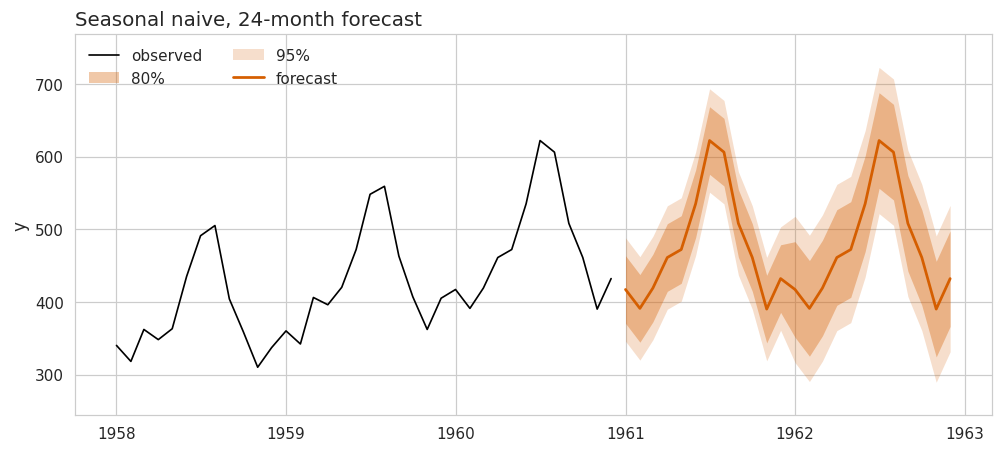

In [9]:
P.fan_chart(df, floor_fc.rename(columns={
            "SeasonalNaive": "mean",
            "SeasonalNaive-lo-20": "lo-20",
            "SeasonalNaive-lo-40": "lo-40",
            "SeasonalNaive-lo-60": "lo-60",
            "SeasonalNaive-lo-80": "lo-80",
            "SeasonalNaive-lo-95": "lo-95",
            "SeasonalNaive-hi-20": "hi-20",
            "SeasonalNaive-hi-40": "hi-40",
            "SeasonalNaive-hi-60": "hi-60",
            "SeasonalNaive-hi-80": "hi-80",
            "SeasonalNaive-hi-95": "hi-95",
            "ds": "ds"}),
            title="Seasonal naive, 24-month forecast",
            history_tail=36, levels=(80, 95))
plt.show()

The seasonal naive repeats the last year's monthly values, so it keeps the yearly pattern but does not extend the upward trend. The 95% prediction band is wider than the 80% band, and both widen in the second forecast year. We still need cross-validation to check whether the 80% band actually covers close to 80% of observations.

**2.1 What is left on the table.** The floor's in-sample residuals are
``y_t - y_{t-12}`` over the series. Plot them, then their ACF (24 lags). Is
there a trend left? Correlation at the low lags? At 12? If it is not white
noise, what structure is it, and which kind of model eats that structure?

/tmp/ipykernel_923/1465492114.py:10: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


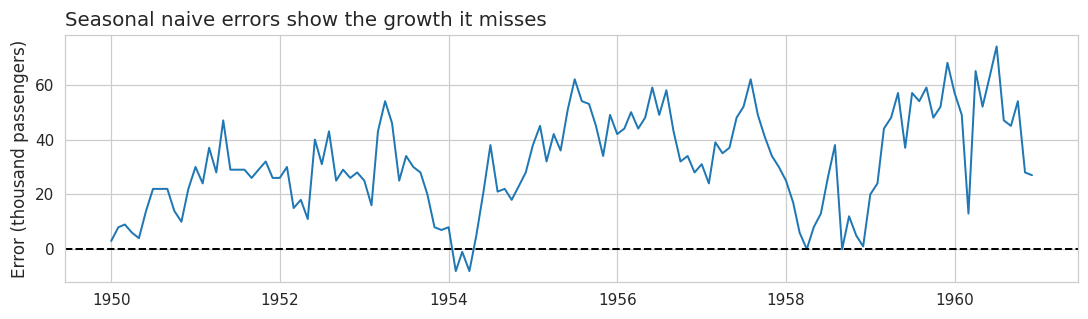

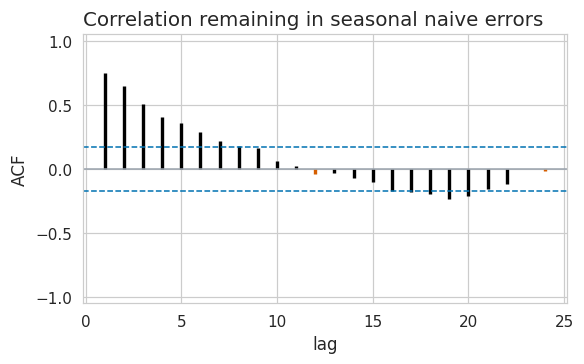

In [10]:
resid_floor = df["y"] - df["y"].shift(SEASON_LENGTH)
valid = resid_floor.notna()

plt.figure(figsize=(10, 3))
plt.plot(df.loc[valid, "ds"], resid_floor.loc[valid])
plt.axhline(0, color="black", linestyle="--")
plt.title("Seasonal naive errors show the growth it misses")
plt.ylabel("Error (thousand passengers)")
plt.xlabel("")
plt.tight_layout()
plt.show()

P.acf_plot(
    resid_floor.dropna(),
    nlags=24,
    highlight_every=SEASON_LENGTH,
    title="Correlation remaining in seasonal naive errors"
)
plt.show()

Most residuals are positive, showing that the seasonal naive usually underestimates passenger numbers because it misses growth. The ACF shows strong positive correlation at short lags, but no clear positive spike at lag 12. These errors are not random noise, so a model with a trend component or ARIMA terms may capture some of the remaining structure.

---
# 3. Your model: the framework

AutoGluon fits a zoo of models behind one call - every model in the zoo
below is a model you have met in this course. The install is large, so this
runs on Colab.

> Every cell in this section is **skip-guarded**: without `autogluon`
> installed it prints why and moves on, so the rest of the notebook still
> runs.

In [11]:
%pip install -q "autogluon.timeseries"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.4/274.4 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.7/90.7 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.4/248.4 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.3/112.3 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 514.8/514.8 kB 30.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 285.4/285.4 kB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 864.0/864.0 kB 47.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 49.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [12]:
import importlib.util

HAS_AG = importlib.util.find_spec("autogluon") is not None
if not HAS_AG:
    print("autogluon is not installed. On Colab, run this and re-run the cell:")
    print("    !pip install -q 'autogluon.timeseries'")
    print("\n(Takes a few minutes. A runtime reset wipes it.)")
else:
    print("autogluon is available")

autogluon is available


**3.1 The data conversion stays visible.** AutoGluon has its own
frame, its own column names, its own fit loop and its own leaderboard.
Writing it out by hand once is the point - the gap between two APIs doing
the same job is the thing to notice.

| | this course | AutoGluon |
|---|---|---|
| id column | `unique_id` | `item_id` |
| time column | `ds` | `timestamp` |
| value column | `y` | `target` (nameable) |
| frame | `pd.DataFrame` | `TimeSeriesDataFrame` |

In [13]:
if HAS_AG:
    from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

    # Long format to AutoGluon's long format: the same three columns, renamed.
    ag_long = df.rename(columns={"unique_id": "item_id", "ds": "timestamp"})
    tsdf = TimeSeriesDataFrame.from_data_frame(
        ag_long, id_column="item_id", timestamp_column="timestamp")

    # One 12-month holdout, cut the way AutoGluon expects.
    ag_train = tsdf.slice_by_timestep(None, -12)

    print(tsdf.head(3))
    print(f"\nfull: {len(tsdf)} rows   train: {len(ag_train)} rows")

                                               y
item_id                        timestamp        
Air passengers (Box & Jenkins) 1949-01-01  112.0
                               1949-02-01  118.0
                               1949-03-01  132.0

full: 144 rows   train: 132 rows


In [14]:
if HAS_AG:
    ZOO = {
        "Naive": {},
        "SeasonalNaive": {},
        "AutoETS": {},
        "AutoARIMA": {}
    }

    predictor = TimeSeriesPredictor(
        prediction_length=12,
        target="y",
        eval_metric="MASE",
        freq="MS",
        verbosity=1
    )

    predictor.fit(
        ag_train,
        hyperparameters=ZOO,
        time_limit=120
    )

In [15]:
if HAS_AG:
    leaderboard = predictor.leaderboard(tsdf)
    display(leaderboard)

,model,score_test,score_val,pred_time_test,pred_time_val,fit_time_marginal,fit_order
0,AutoARIMA,-0.608073,-1.575987,0.179125,0.193800,0.013923,4
1,WeightedEnsemble,-0.929514,-1.535792,0.283851,0.302147,0.291590,5
2,AutoETS,-1.169539,-1.554323,0.102867,0.106880,0.012169,3
3,SeasonalNaive,-1.570881,-1.656513,0.009585,0.006537,0.011752,2
4,Naive,-2.495895,-3.196371,0.014830,0.007283,0.017362,1


**3.2 Read what it handed back.** What is the *sign* of `score_val`, and
what does the answer to "how many windows" mean for how much you should
trust this ranking? It decides what the next section does with this table.
And: does the shortlist agree with the shape you read in section 1?

AutoGluon reports negative MASE scores, so values closer to zero are better. WeightedEnsemble has the best internal validation score (-1.536), while AutoARIMA performs best on the separate final 12-month holdout (-0.608).

The internal ranking uses only one validation window, so it may change across different periods. We therefore test AutoARIMA against SeasonalNaive and Naive using eight rolling-origin windows.

AutoARIMA is a reasonable candidate because the series shows strong growth, yearly seasonality, and autocorrelation. Theta was excluded after a fitting failure caused it to fall back to SeasonalNaive.

---
# 4. The harness

The framework's ranking came from one internal split. One holdout is not a
ranking. So the shortlist goes through the rolling-origin harness: eight
origins, twelve months each, the whole distribution scored - and the floor
stays in the table.

In [16]:
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive, Naive

sf_cv = StatsForecast(
    models=[
        SeasonalNaive(season_length=SEASON_LENGTH),
        Naive()
    ],
    freq="MS",
    n_jobs=1
)

cv = sf_cv.cross_validation(
    df=df,
    h=H,
    step_size=H,
    n_windows=8,
    level=scoring.LEVELS
)

display(cv.head())

,unique_id,ds,cutoff,y,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,...,Naive-lo-20,Naive-lo-40,Naive-lo-60,Naive-lo-80,Naive-lo-95,Naive-hi-20,Naive-hi-40,Naive-hi-60,Naive-hi-80,Naive-hi-95
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,171.0,164.48674,157.518271,149.362895,138.052796,120.6116,...,189.949480,185.615870,180.544137,173.510518,162.664042,198.050520,202.384130,207.455863,214.489482,225.335958
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,180.0,173.48674,166.518271,158.362895,147.052796,129.6116,...,188.271699,182.143050,174.970536,165.023497,149.684263,199.728301,205.856950,213.029464,222.976503,238.315737
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,193.0,186.48674,179.518271,171.362895,160.052796,142.6116,...,186.984293,179.478261,170.693761,158.511177,139.724529,201.015707,208.521739,217.306239,229.488823,248.275471
3,Air passengers (Box & Jenkins),1953-04-01,1952-12-01,235.0,181.0,174.48674,167.518271,159.362895,148.052796,130.6116,...,185.898959,177.231740,167.088273,153.021037,131.328084,202.101041,210.768260,220.911727,234.978963,256.671916
4,Air passengers (Box & Jenkins),1953-05-01,1952-12-01,229.0,183.0,176.48674,169.518271,161.362895,150.052796,132.6116,...,184.942761,175.252516,163.911775,148.184126,123.930668,203.057239,212.747484,224.088225,239.815874,264.069332


In [17]:
from statsforecast.models import AutoARIMA

MY_MODEL = AutoARIMA(season_length=SEASON_LENGTH)
MY_NAME = "AutoARIMA"

mysf = StatsForecast(
    models=[MY_MODEL],
    freq="MS",
    n_jobs=1
)

mycv = mysf.cross_validation(
    df=df,
    h=H,
    step_size=H,
    n_windows=8,
    level=scoring.LEVELS
)

display(
    mycv[
        ["ds", "cutoff", "y", MY_NAME]
    ].head()
)

,ds,cutoff,y,AutoARIMA
0,1953-01-01,1952-12-01,196.0,200.033960
1,1953-02-01,1952-12-01,196.0,205.951260
2,1953-03-01,1952-12-01,236.0,228.492818
3,1953-04-01,1952-12-01,235.0,214.413179
4,1953-05-01,1952-12-01,229.0,220.835055


In [18]:
evaluations = [
    ("SeasonalNaive", cv),
    ("Naive", cv),
    (MY_NAME, mycv)
]

RESULTS = pd.DataFrame({
    name: scoring.score_cv(
        cv=forecast_cv,
        model=name,
        train_df=df,
        seasonality=SEASON_LENGTH,
        level=80
    )
    for name, forecast_cv in evaluations
}).T

RESULTS.index.name = "model"

display(RESULTS.round(3))

,mase,rmsse,crps,coverage_80,mase_min,mase_max
model,,,,,,
SeasonalNaive,1.313,1.246,0.062,0.510,0.412,1.959
Naive,2.119,2.452,0.110,0.688,1.422,3.196
AutoARIMA,0.647,0.683,0.034,0.698,0.330,1.594


**4.1 Read the table.** Does the harness confirm the leaderboard's
shortlist, or does it move it? For each model: where does it beat the
floor, where does it lose, and on which of the three metrics? A model that
wins the point forecast and loses the distribution is a real result -
report both halves. And what does each model's 80% coverage say about its
band?

Across eight rolling-origin windows, AutoARIMA has the lowest MASE (0.647), RMSSE (0.683), and scaled CRPS (0.034). It improves on the seasonal naive benchmark in both point forecasts and distributional accuracy. Naive has higher errors than the seasonal benchmark on all three measures.

However, none of the models reaches the nominal 80% interval coverage. AutoARIMA covers 69.8% of observations, compared with 51.0% for SeasonalNaive and 68.8% for Naive. AutoARIMA is the strongest candidate among these models, but its intervals underestimate uncertainty and need calibration.

/tmp/ipykernel_923/3029365308.py:24: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


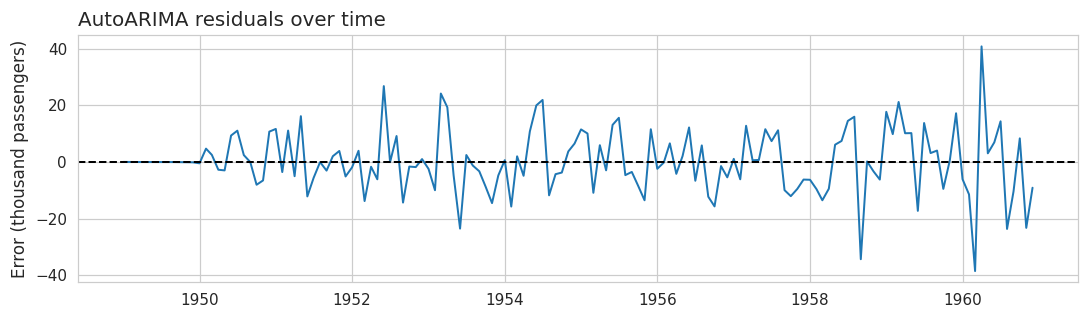

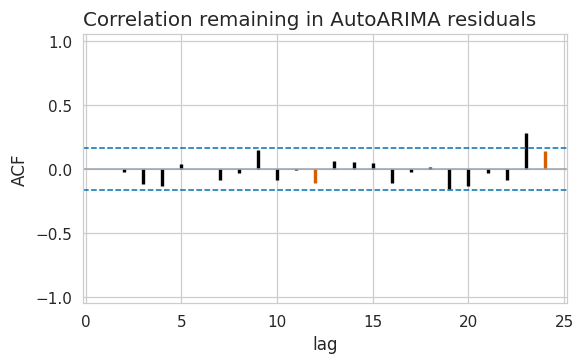

In [19]:
final_model = AutoARIMA(
    season_length=SEASON_LENGTH
)

final_output = final_model.forecast(
    y=df["y"].to_numpy(),
    h=H_REPORT,
    level=scoring.LEVELS,
    fitted=True
)

resid_model = pd.Series(
    df["y"].to_numpy() - final_output["fitted"],
    index=df["ds"],
    name="residual"
).dropna()

plt.figure(figsize=(10, 3))
plt.plot(resid_model.index, resid_model.values)
plt.axhline(0, color="black", linestyle="--")
plt.title("AutoARIMA residuals over time")
plt.ylabel("Error (thousand passengers)")
plt.xlabel("")
plt.tight_layout()
plt.show()

P.acf_plot(
    resid_model,
    nlags=24,
    highlight_every=SEASON_LENGTH,
    title="Correlation remaining in AutoARIMA residuals"
)
plt.show()

The residual ACF shows no spikes outside the approximate confidence bounds through lag 24. This suggests that AutoARIMA has captured much of the temporal dependence left by the seasonal naive benchmark. However, this does not guarantee accurate prediction intervals: its observed 80% interval coverage is only 69.8%.

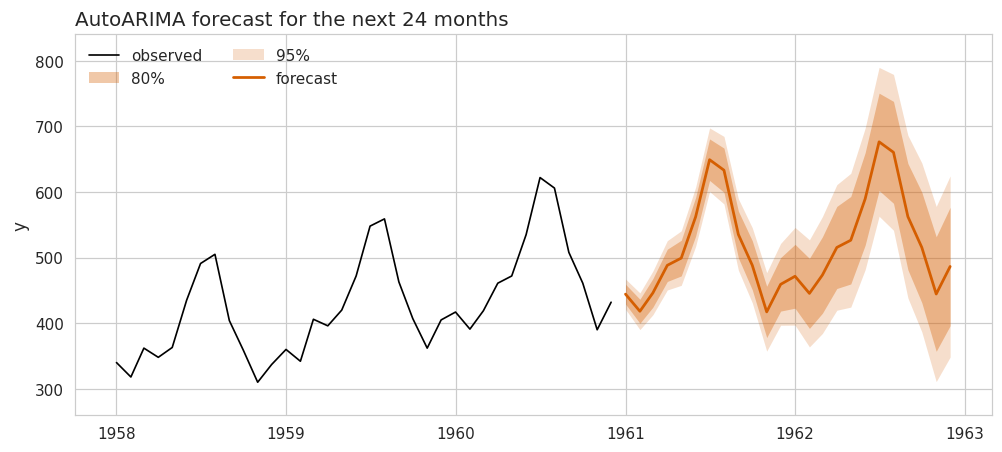

,ds,mean,lo-80,hi-80,width_80,width_95
0,1961-01-01,444.31,429.25,459.37,30.12,46.06
11,1961-12-01,459.24,418.45,500.02,81.57,124.74
23,1962-12-01,486.47,396.20,576.74,180.54,276.12


In [20]:
final_fc = pd.DataFrame({
    "unique_id": df["unique_id"].iloc[0],
    "ds": pd.date_range(
        start=df["ds"].max() + pd.offsets.MonthBegin(1),
        periods=H_REPORT,
        freq="MS"
    ),
    "mean": final_output["mean"]
})

for level in scoring.LEVELS:
    for side in ["lo", "hi"]:
        column = f"{side}-{level}"
        final_fc[column] = final_output[column]

P.fan_chart(
    df,
    final_fc,
    title="AutoARIMA forecast for the next 24 months",
    history_tail=36,
    levels=(80, 95)
)
plt.show()

interval_summary = final_fc[
    ["ds", "mean", "lo-80", "hi-80"]
].copy()

interval_summary["width_80"] = (
    final_fc["hi-80"] - final_fc["lo-80"]
)

interval_summary["width_95"] = (
    final_fc["hi-95"] - final_fc["lo-95"]
)

display(
    interval_summary.iloc[[0, 11, 23]].round(2)
)

---
# 5. The report

The notebook is evidence; the report is the claim. Two to three pages, for a
manager who will not open the notebook:

- **The recommendation.** Which model you would ship, in one sentence, and
  the one number that earns it.
- **The intervals.** How wide, what they covered, and whether the band is
  honest. Coverage is the check a band cannot do alone.
- **The residuals.** What the floor - and your model - missed. A residual
  ACF is a fact; a sentence about what it means is the deliverable.
- **One change.** A specific next step - data, driver, frequency, horizon -
  and what you expect it to do.

Rules: every number in the report comes out of this notebook; no number
that could not have come out of the harness counts; no leakage - a fold's
fit and its denominator use only data that fold was allowed to see.

**Optional, for extra credit.** The series is a total across origins, so a
driver is a modelling choice, not a lookup: pick a region and pull its
monthly mean temperature from a public weather archive (for example
Open-Meteo's historical API - free, no key), cache it next to the CSV, and
regress on it. That is dynamic regression - and the cross-validation
discipline still applies to the regression's residuals.